# Phase 2 — Collisions aggregated by ZIP × year
**Contributor:** Yassin · GIU ICS503 · NYC Build and Crash  
**Input:** `data/collisions_step2.csv.gz` — Ahmed's cleaned, crash-level export.  
**Output:** `data/collisions_zip_year.csv` — one observed row per `(zip_code, year)`.

**Team window:** January 1, 2022 through October 31, 2026, implemented as
`2022-01-01 <= crash_date < 2026-11-01` before any ZIP exclusions or aggregation.
The source may have earlier/later records or revised historical counts; no hash or snapshot count is
required for acceptance. Structure, identifiers, types, scope and reconciliation checks remain strict.
The notebook never downloads data, reruns Ahmed's pipeline, or alters the source gzip.

## How to run
Use VS Code with a repository-root kernel and the project `.venv`, installed with
`pip install -r requirements.txt`. Tested with Python 3.14.8. Restart Kernel and Run All.
The local Stage 2 handoff must exist. Transfer instructions and the reproducibility test method are
in the handoff section; a missing handoff does not trigger an automatic API download.
Generated data/tests remain ignored. An identical output is reused; archive a different old derived
CSV before intentionally regenerating it. Never remove the Stage 2 input.


**Datasets used (NYC Open Data):** [DOB NOW: Build Job Application Filings (w9ak-ipjd)](https://data.cityofnewyork.us/d/w9ak-ipjd) and [Motor Vehicle Collisions, Crashes (h9gi-nx95)](https://data.cityofnewyork.us/d/h9gi-nx95).

## 1. Why aggregate before the join?
A crash and a building application describe different events. Joining individual records merely
because ZIP and year match would multiply each crash by the number of applications in that cell,
inflating both domains' counts. Each side must first produce a unique ZIP/year summary; Issa can then
join the summaries with one-to-one key validation.

ZIP provides the shared geographic identifier, and calendar year aligns filing and collision dates
at a practical common grain. A filing year is not a construction completion year. This is a study of
**association**, with no causal inference or traffic-exposure denominator. This notebook does not
join housing, complete an absent ZIP/year grid, annualize partial years, or invent geographic values.

Missing ZIPs are excluded **only from this geographic aggregate**. Their original rows and casualty
values remain in Ahmed's gzip for citywide analysis. A modal borough summarizes observed labels;
it is not a recovered location or a replacement in the source records.


In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import gzip
from datetime import datetime, timezone
import os
import subprocess
import tempfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

PROJECT_ROOT = Path.cwd()
NOTEBOOK_NAME = 'phase2_collisions_aggregation_yassin.ipynb'
INPUT_PATH = Path('data/collisions_step2.csv.gz')
OUTPUT_PATH = Path('data/collisions_zip_year.csv')
VALIDATION_DIR = Path('data/validation/phase2')
assert (PROJECT_ROOT / NOTEBOOK_NAME).is_file(), 'Start the kernel in the repository root'
assert INPUT_PATH.is_file(), 'Generate/obtain Ahmed\'s verified Stage 2 handoff before running'
VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

KEYS = ['zip_code', 'year']
CASUALTY_MAP = {
    'persons_injured': 'number_of_persons_injured',
    'persons_killed': 'number_of_persons_killed',
    'pedestrians_injured': 'number_of_pedestrians_injured',
    'pedestrians_killed': 'number_of_pedestrians_killed',
    'cyclist_injured': 'number_of_cyclist_injured',
    'cyclist_killed': 'number_of_cyclist_killed',
    'motorist_injured': 'number_of_motorist_injured',
    'motorist_killed': 'number_of_motorist_killed',
}
SOURCE_COUNTS = list(CASUALTY_MAP.values())
FLAGS = ['extreme_injury', 'is_partial_year', 'zip_missing']
FACTOR_COLUMNS = [f'contributing_factor_vehicle_{i}' for i in range(1, 6)]
VEHICLE_COLUMNS = ['vehicle_type_code1', 'vehicle_type_code2', 'vehicle_type_code_3',
                   'vehicle_type_code_4', 'vehicle_type_code_5']
EXPECTED_INPUT_COLUMNS = [
    'collision_id', 'crash_date', 'crash_time', 'year', 'month', 'hour', 'is_partial_year',
    'borough', 'zip_code', 'zip_missing', 'latitude', 'longitude',
] + SOURCE_COUNTS + ['extreme_injury'] + FACTOR_COLUMNS + VEHICLE_COLUMNS
COUNT_COLUMNS = ['collision_count'] + list(CASUALTY_MAP) + ['extreme_injury_count']
OUTPUT_COLUMNS = ['zip_code', 'year', 'borough'] + COUNT_COLUMNS + ['top_contributing_factor', 'is_partial_year']
BOROUGHS = {'Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island'}
INT64_MAX = np.iinfo(np.int64).max
SCOPE_START = pd.Timestamp('2022-01-01')
SCOPE_END = pd.Timestamp('2026-11-01')  # exclusive: agreed last day is October 31

def file_sha256(path):
    """Hash the complete file without changing it."""
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def require(condition, message):
    """Raise a clear validation failure; never silently repair an incompatible handoff."""
    if not bool(condition):
        raise ValueError(message)

def parse_boolean_text(series, name):
    """Accept only literal CSV True/False; never use truthiness of nonempty strings."""
    require(series.notna().all() and series.isin(['True', 'False']).all(),
            f'{name}: expected nonmissing literal True/False values')
    return series.map({'True': True, 'False': False}).astype(bool)

def read_stage2(path):
    """Load the local handoff with explicit identifiers, Booleans, and strict date parsing."""
    types = {c: 'string' for c in ['zip_code', 'collision_id', 'borough'] + FACTOR_COLUMNS + VEHICLE_COLUMNS + FLAGS}
    frame = pd.read_csv(path, dtype=types, keep_default_na=False, na_values=[''])
    require(frame.columns.tolist() == EXPECTED_INPUT_COLUMNS, 'Unexpected Stage 2 schema/order; report it before proceeding')
    for column in FLAGS:
        frame[column] = parse_boolean_text(frame[column], column)
    frame['crash_date'] = pd.to_datetime(frame['crash_date'], errors='raise')
    return frame

def validate_source_frame(frame):
    """Validate the agreed crash-level contract without altering any input values."""
    require(frame.columns.tolist() == EXPECTED_INPUT_COLUMNS, 'Source schema differs from the Stage 2 contract')
    require(not frame.empty, 'The source handoff is empty')
    ids = frame['collision_id']
    require(ids.notna().all() and ids.map(lambda x: isinstance(x, str) and bool(x.strip())).all(), 'Missing/blank/nontext collision ID')
    require(not ids.duplicated().any(), 'Duplicate collision IDs: investigate rather than dropping them here')
    dates = pd.to_datetime(frame['crash_date'], errors='raise')
    require(dates.notna().all(), 'Missing crash date; report the source issue before filtering')
    require(dates.eq(dates.dt.normalize()).all(), 'Unexpected non-midnight crash_date representation')
    require(pd.api.types.is_integer_dtype(frame['year']) and frame['year'].eq(dates.dt.year).all(), 'Year must be integer and match crash_date')
    require(frame['month'].eq(dates.dt.month).all(), 'Month differs from crash_date')
    require(pd.api.types.is_integer_dtype(frame['hour']) and frame['hour'].between(0, 23).all(), 'Invalid hour')
    zips = frame['zip_code'].dropna()
    require(all(isinstance(x, str) for x in zips) and zips.str.fullmatch(r'[0-9]{5}').all(), 'ZIP must be exactly five text digits')
    require(zips.between('10001', '11697').all(), 'ZIP outside Ahmed\'s validated range; investigate source')
    boroughs = frame['borough'].dropna()
    require(boroughs.isin(BOROUGHS).all(), 'Unexpected borough spelling/case; do not invent a mapping')
    for column in FLAGS:
        require(pd.api.types.is_bool_dtype(frame[column]) and frame[column].notna().all(), f'{column} must contain nonmissing Booleans')
    require(frame['zip_missing'].eq(frame['zip_code'].isna()).all(), 'zip_missing flag disagrees with ZIP nulls')
    latest = dates.max()
    require(frame.groupby('year')['is_partial_year'].nunique().le(1).all(), 'Source partial-year flag varies within one year')
    flagged_years = set(frame.loc[frame['is_partial_year'], 'year'])
    require(flagged_years <= {int(latest.year)}, 'Source flags a year before its latest year as partial')
    for column in SOURCE_COUNTS:
        values = frame[column]
        require(pd.api.types.is_numeric_dtype(values) and not pd.api.types.is_bool_dtype(values), f'{column} is not numeric casualty data')
        require(values.notna().all() and np.isfinite(values.to_numpy(dtype='float64')).all(), f'{column} contains missing/nonfinite counts')
        require(values.ge(0).all() and values.mod(1).eq(0).all(), f'{column} contains negative/fractional counts')
        require(int(values.max()) <= INT64_MAX, f'{column} exceeds int64 range')
    require(frame['extreme_injury'].eq(frame['number_of_persons_injured'].ge(15)).all(), 'extreme_injury flag differs from >=15 injured')
    for total, parts in [
        ('number_of_persons_injured', ['number_of_pedestrians_injured', 'number_of_cyclist_injured', 'number_of_motorist_injured']),
        ('number_of_persons_killed', ['number_of_pedestrians_killed', 'number_of_cyclist_killed', 'number_of_motorist_killed']),
    ]:
        # Python integer addition avoids overflow even while validating an incompatible source.
        parts_sum = frame[parts].apply(lambda row: sum(int(v) for v in row), axis=1)
        require(frame[total].ge(parts_sum).all(), f'{total} is below its road-user subgroup sum')
    return True


def apply_common_scope(frame):
    """Bound a validated source before any ZIP exclusion; preserve original rows and bytes."""
    dates = frame['crash_date']
    keep = dates.ge(SCOPE_START) & dates.lt(SCOPE_END)
    scoped = frame.loc[keep].copy()
    require(not scoped.empty, 'No records fall within the agreed common window')
    latest = scoped['crash_date'].max()
    # Capping a later extract in October makes 2026 partial even if the uncapped file
    # regards it as complete. An older handoff may end earlier; report that extent.
    partial = int(latest.year) if latest < pd.Timestamp(year=latest.year, month=12, day=31) else None
    bounded_flags = scoped['year'].eq(partial)
    changed_flags = int(scoped['is_partial_year'].ne(bounded_flags).sum())
    scoped['is_partial_year'] = bounded_flags.astype(bool)
    require(scoped['crash_date'].ge(SCOPE_START).all() and scoped['crash_date'].lt(SCOPE_END).all(), 'Filtered dates outside common window')
    require(scoped['year'].between(SCOPE_START.year, SCOPE_END.year).all(), 'Filtered year outside common window')
    summary = {'rows_before': len(frame), 'rows_after': len(scoped),
               'excluded_before_start': int(dates.lt(SCOPE_START).sum()),
               'excluded_on_or_after_end': int(dates.ge(SCOPE_END).sum()),
               'excluded_total': int((~keep).sum()), 'partial_flag_changes': changed_flags}
    assert summary['rows_before'] == summary['rows_after'] + summary['excluded_total']
    assert summary['excluded_total'] == summary['excluded_before_start'] + summary['excluded_on_or_after_end']
    return scoped, summary, partial


## 2. Load and validate the handoff
ZIP and collision identifiers are strings. Parse Boolean CSV values explicitly and validate the
complete input schema, dates, identifier uniqueness and nonnegative integral casualty counts.
SHA-256 is recorded only for provenance and to confirm that this run did not modify the input;
it is never compared with a required file hash. No snapshot-specific record totals are asserted.

### Scope filter
Keep `2022-01-01 <= crash_date < 2026-11-01` immediately after input validation and before ZIP
exclusions. Print both source extents, every date exclusion and the per-year retained counts.
Missing-ZIP percentages and all metrics below use this filtered frame.

Partial-year flags are validated in the incoming handoff and then aligned to the filtered coverage
on a copy. A later source may label 2026 complete, but our October cutoff makes it partial. An older
source may end earlier; its actual extent is reported rather than assumed to reach the common end.


In [2]:
input_hash_before = file_sha256(INPUT_PATH)
source_all = read_stage2(INPUT_PATH)
validate_source_frame(source_all)
source, scope_summary, partial_year = apply_common_scope(source_all)
source_dates = source['crash_date']
latest_date = source_dates.max()
latest_year = int(latest_date.year)
print('Run UTC:', datetime.now(timezone.utc).isoformat())
print('Input provenance: supplied local Stage 2 handoff; no API retrieval by this notebook.')
print('Input:', INPUT_PATH)
print('Unfiltered rows / columns:', source_all.shape)
print('Unfiltered dates:', source_all['crash_date'].min().date(), 'through', source_all['crash_date'].max().date())
display(pd.DataFrame([scope_summary]))
print('Scope rows before / after / excluded:', scope_summary['rows_before'], scope_summary['rows_after'], scope_summary['excluded_total'])
print('Filtered rows / columns:', source.shape)
print('Filtered crash dates:', source_dates.min().date(), 'through', latest_date.date())
print('Unique filtered collision IDs:', source['collision_id'].nunique())
print('Input SHA-256 (provenance only):', input_hash_before)
print('Filtered records by year:')
display(source.groupby('year').size().rename('crashes_in_scope').to_frame())
display(source.dtypes.rename('loaded_dtype').to_frame())


Run UTC: 2026-11-09T05:09:06.246375+00:00
Input provenance: supplied local Stage 2 handoff; no API retrieval by this notebook.
Input: data\collisions_step2.csv.gz
Unfiltered rows / columns: (448091, 31)
Unfiltered dates: 2022-01-01 through 2026-11-03


,rows_before,rows_after,excluded_before_start,excluded_on_or_after_end,excluded_total,partial_flag_changes
0,448091,447497,0,594,594,0


Scope rows before / after / excluded: 448091 447497 594
Filtered rows / columns: (447497, 31)
Filtered crash dates: 2022-01-01 through 2026-10-31
Unique filtered collision IDs: 447497
Input SHA-256 (provenance only): daed82379e27e13790682b02070842ead4f9a52e41abe4eb67bdba9447d146df
Filtered records by year:


,crashes_in_scope
year,
2022,103888
2023,96608
2024,91316
2025,85559
2026,70126


,loaded_dtype
collision_id,string
crash_date,datetime64[us]
crash_time,str
year,int64
month,int64
hour,int64
is_partial_year,bool
borough,string
zip_code,string
zip_missing,bool


## 3. Missing ZIP exclusions and selection bias
A record without a ZIP cannot be assigned to a ZIP/year cell. Exclude it only from the geographic
summary after the common date filter, preserving the original gzip. Print record exclusions and all
eight excluded casualty totals: exclusion is not equivalent to zero collisions or zero casualties.

Coverage is uneven by year. The exact percentages below are recalculated from this run's filtered
records. Earlier-year ZIP undercoverage can distort time comparisons; variation in reporting
completeness is not evidence of a change in road safety.


In [3]:
def summarize_exclusions(frame):
    """Reconcile input, eligible and excluded records/casualties without imputing geography."""
    missing = frame['zip_code'].isna()
    by_year = frame.groupby('year', sort=True).agg(
        input_records=('collision_id', 'size'), excluded_missing_zip=('zip_missing', 'sum'))
    by_year['valid_zip_records'] = by_year['input_records'] - by_year['excluded_missing_zip']
    by_year['excluded_percent'] = 100 * by_year['excluded_missing_zip'] / by_year['input_records']
    by_year = by_year.reset_index()
    casualty_rows = []
    for output, column in CASUALTY_MAP.items():
        all_total = sum(int(x) for x in frame[column])
        excluded = sum(int(x) for x in frame.loc[missing, column])
        eligible_total = sum(int(x) for x in frame.loc[~missing, column])
        assert all_total == eligible_total + excluded
        casualty_rows.append({'metric': output, 'all_records': all_total,
                              'eligible_records': eligible_total, 'excluded_missing_zip': excluded})
    assert int(by_year['input_records'].sum()) == len(frame)
    assert int(by_year['excluded_missing_zip'].sum()) == int(missing.sum())
    assert int(by_year['valid_zip_records'].sum()) + int(missing.sum()) == len(frame)
    return by_year, pd.DataFrame(casualty_rows)

eligible = source.loc[source['zip_code'].notna()].copy()
excluded = source.loc[source['zip_code'].isna()]
year_coverage, casualty_coverage = summarize_exclusions(source)
print(f'Input: {len(source):,}; excluded missing ZIP: {len(excluded):,} ({len(excluded) / len(source):.6%}); eligible: {len(eligible):,}')
display(year_coverage.round({'excluded_percent': 6}))
display(casualty_coverage)


Input: 447,497; excluded missing ZIP: 126,405 (28.247117%); eligible: 321,092


,year,input_records,excluded_missing_zip,valid_zip_records,excluded_percent
0,2022,103888,35144,68744,33.828739
1,2023,96608,30920,65688,32.005631
2,2024,91316,26145,65171,28.631346
3,2025,85559,17091,68468,19.975689
4,2026,70126,17105,53021,24.391809


,metric,all_records,eligible_records,excluded_missing_zip
0,persons_injured,251858,169577,82281
1,persons_killed,1260,720,540
2,pedestrians_injured,44142,35905,8237
3,pedestrians_killed,568,372,196
4,cyclist_injured,24009,19336,4673
5,cyclist_killed,87,61,26
6,motorist_injured,170792,103850,66942
7,motorist_killed,484,205,279


## 4. Metric definitions and category decisions
Every output row represents an **observed** ZIP/year with at least one eligible crash. Count columns
use `int64`. No absent ZIP/year cells are generated or filled with zero.

| Output column | Definition |
|---|---|
| `zip_code` | Source five-digit string; no imputation |
| `year` | Integer crash calendar year |
| `collision_count` | Number of eligible crash records, not number of injured people |
| `persons_injured` | Sum of `number_of_persons_injured` |
| `persons_killed` | Sum of `number_of_persons_killed` |
| `pedestrians_injured` | Sum of `number_of_pedestrians_injured` |
| `pedestrians_killed` | Sum of `number_of_pedestrians_killed` |
| `cyclist_injured` | Sum of `number_of_cyclist_injured` |
| `cyclist_killed` | Sum of `number_of_cyclist_killed` |
| `motorist_injured` | Sum of `number_of_motorist_injured` |
| `motorist_killed` | Sum of `number_of_motorist_killed` |
| `extreme_injury_count` | Sum of verified Boolean `extreme_injury` (persons injured ≥15); these crashes stay in all totals |
| `top_contributing_factor` | Modal informative `contributing_factor_vehicle_1` within this ZIP/year |
| `borough` | Modal nonmissing borough **per ZIP across all eligible years**, then mapped onto each ZIP/year |
| `is_partial_year` | Verified source flag, uniform within each year/group; latest observed year is incomplete |

For factors, strip/collapse whitespace and exclude missing/empty values, `Unspecified`, and
`Does Not Apply`, with case-insensitive exclusions. Retain other category spellings. If no informative
value remains, export a genuine missing value (empty CSV field), never a fictional label.

For either category mode, break equal-frequency ties by **case-insensitive alphabetical order**, then
exact spelling. This is deterministic and independent of input order. Borough values remain Title Case.
All observed ZIP/borough conflicts and vote counts are printed below; choosing a representative label
does not erase minority labels from the source or establish an authoritative geographic boundary.


In [4]:
def informative_factors(values):
    """Normalize whitespace and exclude only missing/empty and named non-informative factors."""
    text = values.astype('string').str.strip().str.replace(r'\s+', ' ', regex=True)
    excluded = text.isna() | text.eq('') | text.str.casefold().isin({'unspecified', 'does not apply'})
    return text.mask(excluded, pd.NA)

def deterministic_mode(values):
    """Frequency first; ties use casefolded alphabetical order then exact spelling."""
    frequencies = values.dropna().astype('string').value_counts(sort=False)
    if frequencies.empty:
        return pd.NA
    candidates = pd.DataFrame({'label': frequencies.index.tolist(), 'votes': frequencies.to_numpy()})
    candidates['casefold'] = candidates['label'].str.casefold()
    return candidates.sort_values(['votes', 'casefold', 'label'], ascending=[False, True, True], kind='stable').iloc[0]['label']

def borough_decisions(eligible_frame):
    """Select one observed modal borough per ZIP across years and expose every conflicting label."""
    modes = eligible_frame.groupby('zip_code', sort=True)['borough'].agg(deterministic_mode).astype('string')
    votes = eligible_frame.dropna(subset=['borough']).groupby(['zip_code', 'borough'], sort=True).size().rename('records').reset_index()
    distinct = votes.groupby('zip_code')['borough'].nunique()
    conflicts = votes.loc[votes['zip_code'].isin(distinct[distinct > 1].index)].copy()
    conflicts['known_borough_records_for_zip'] = conflicts.groupby('zip_code')['records'].transform('sum')
    conflicts['share_percent'] = 100 * conflicts['records'] / conflicts['known_borough_records_for_zip']
    conflicts['selected_borough'] = conflicts['zip_code'].map(modes)
    conflicts['selected'] = conflicts['borough'].eq(conflicts['selected_borough'])
    return modes, conflicts.reset_index(drop=True)

def empty_aggregate():
    """A source with no eligible ZIPs produces zero rows, never invented geographic cells."""
    return pd.DataFrame({c: pd.Series(dtype=('string' if c in ['zip_code', 'borough', 'top_contributing_factor']
                                            else 'bool' if c == 'is_partial_year' else 'int64')) for c in OUTPUT_COLUMNS})

def aggregate_zip_year(frame):
    """Return observed ZIP/year summaries; leave source records untouched."""
    validate_source_frame(frame)
    work = frame.loc[frame['zip_code'].notna()].copy()
    if work.empty:
        return empty_aggregate()
    # Counts are nonnegative. A checked Python-integer grand total bounds every group sum.
    for column in SOURCE_COUNTS:
        require(sum(int(x) for x in work[column]) <= INT64_MAX, f'{column}: aggregate would overflow int64')
        work[column] = work[column].astype('int64')
    work['_informative_factor'] = informative_factors(work['contributing_factor_vehicle_1'])
    specification = {'collision_count': ('collision_id', 'size')}
    specification.update({output: (column, 'sum') for output, column in CASUALTY_MAP.items()})
    specification.update({'extreme_injury_count': ('extreme_injury', 'sum'),
                          'top_contributing_factor': ('_informative_factor', deterministic_mode),
                          'is_partial_year': ('is_partial_year', 'first')})
    result = work.groupby(KEYS, sort=True, observed=True).agg(**specification).reset_index()
    modes, _ = borough_decisions(work)
    result['borough'] = result['zip_code'].map(modes).astype('string')
    for column in ['zip_code', 'top_contributing_factor']:
        result[column] = result[column].astype('string')
    result['year'] = result['year'].astype('int64')
    result[COUNT_COLUMNS] = result[COUNT_COLUMNS].astype('int64')
    result['is_partial_year'] = result['is_partial_year'].astype(bool)
    return result[OUTPUT_COLUMNS].sort_values(KEYS, kind='stable').reset_index(drop=True)

zip_borough_modes, borough_conflicts = borough_decisions(eligible)
print('ZIPs with conflicting nonmissing borough labels:', borough_conflicts['zip_code'].nunique())
display(borough_conflicts.round({'share_percent': 6}))
aggregate = aggregate_zip_year(source)
print('Aggregated rows / columns:', aggregate.shape)
display(aggregate.head(10))


ZIPs with conflicting nonmissing borough labels: 5


,zip_code,borough,records,known_borough_records_for_zip,share_percent,selected_borough,selected
0,11208,Brooklyn,4930,4954,99.515543,Brooklyn,True
1,11208,Queens,24,4954,0.484457,Brooklyn,False
2,11237,Brooklyn,2323,2394,97.034252,Brooklyn,True
3,11237,Queens,71,2394,2.965748,Brooklyn,False
4,11385,Brooklyn,14,4144,0.337838,Queens,False
5,11385,Queens,4130,4144,99.662162,Queens,True
6,11414,Brooklyn,1,896,0.111607,Queens,False
7,11414,Queens,895,896,99.888393,Queens,True
8,11421,Brooklyn,5,1177,0.424809,Queens,False
9,11421,Queens,1172,1177,99.575191,Queens,True


Aggregated rows / columns: (1040, 15)


,zip_code,year,borough,collision_count,persons_injured,persons_killed,pedestrians_injured,pedestrians_killed,cyclist_injured,cyclist_killed,motorist_injured,motorist_killed,extreme_injury_count,top_contributing_factor,is_partial_year
0,10001,2022,Manhattan,517,198,1,77,1,46,0,65,0,0,Driver Inattention/Distraction,False
1,10001,2023,Manhattan,458,185,2,50,1,42,0,82,1,0,Driver Inattention/Distraction,False
2,10001,2024,Manhattan,495,233,0,85,0,62,0,76,0,0,Driver Inattention/Distraction,False
3,10001,2025,Manhattan,551,248,1,89,1,56,0,82,0,0,Driver Inattention/Distraction,False
4,10001,2026,Manhattan,496,229,1,68,0,62,0,79,0,0,Driver Inattention/Distraction,True
5,10002,2022,Manhattan,743,353,1,96,1,85,0,141,0,0,Driver Inattention/Distraction,False
6,10002,2023,Manhattan,750,403,2,95,2,87,0,198,0,0,Driver Inattention/Distraction,False
7,10002,2024,Manhattan,664,338,5,97,5,82,0,146,0,0,Driver Inattention/Distraction,False
8,10002,2025,Manhattan,618,283,1,79,1,63,0,109,0,0,Driver Inattention/Distraction,False
9,10002,2026,Manhattan,583,294,0,83,0,62,0,116,0,0,Driver Inattention/Distraction,True


## 5. Validate keys, sums, categories and partial-year flags
Reconcile every metric to eligible records inside the common window. Recompute category winners
independently with `Counter`, verify all-years ZIP borough decisions, and reject extra ZIP/year cells.
No required record total, ZIP count, group count or casualty sum is tied to a historical snapshot.


In [5]:
def same_label(left, right):
    """Missing is equal only to missing for category verification."""
    return bool(pd.isna(left) and pd.isna(right)) if pd.isna(left) or pd.isna(right) else left == right

def counter_winner(values):
    """Independent mode reference for validation, without the production mode function."""
    counts = Counter(x for x in values if not pd.isna(x))
    if not counts:
        return pd.NA
    maximum = max(counts.values())
    return min((x for x, count in counts.items() if count == maximum), key=lambda x: (x.casefold(), x))

def validate_aggregate(result, frame):
    """Verify the complete aggregate against its source, including all category decisions."""
    require(result.columns.tolist() == OUTPUT_COLUMNS, 'Unexpected aggregate schema/order')
    valid = frame.loc[frame['zip_code'].notna()]
    require(not result.duplicated(KEYS).any(), 'Duplicate output keys: unsafe many-to-many handoff')
    require(result['zip_code'].notna().all() and all(isinstance(x, str) for x in result['zip_code'])
            and result['zip_code'].str.fullmatch(r'[0-9]{5}').all(), 'Output ZIPs must be five-digit strings')
    require(pd.api.types.is_integer_dtype(result['year']) and result['year'].ge(2022).all(), 'Output years invalid')
    expected_keys = set(valid[KEYS].itertuples(index=False, name=None))
    require(set(result[KEYS].itertuples(index=False, name=None)) == expected_keys, 'Missing or invented output keys')
    for column in COUNT_COLUMNS:
        require(str(result[column].dtype) == 'int64' and result[column].notna().all()
                and result[column].ge(0).all(), f'{column}: counts must be nonmissing nonnegative int64')
    require(result['collision_count'].gt(0).all(), 'No zero-filled absent groups are allowed')
    require(sum(int(x) for x in result['collision_count']) == len(valid), 'Collision counts do not reconcile')
    for output, column in CASUALTY_MAP.items():
        require(sum(int(x) for x in result[output]) == sum(int(x) for x in valid[column]), f'{output} total differs from eligible source')
    require(int(result['extreme_injury_count'].sum()) == int(valid['extreme_injury'].sum()), 'Extreme-injury totals differ')
    require(result['extreme_injury_count'].le(result['collision_count']).all(), 'Extreme crashes exceed all crashes')
    require(pd.api.types.is_bool_dtype(result['is_partial_year']) and result['is_partial_year'].notna().all(), 'Partial flag must be Boolean')
    reference_borough = {z: counter_winner(g['borough']) for z, g in valid.groupby('zip_code', sort=True)}
    lookup = result.set_index(KEYS)
    for key, group in valid.groupby(KEYS, sort=True):
        row = lookup.loc[key]
        require(int(row['collision_count']) == len(group), f'{key}: collision count differs')
        for output, column in CASUALTY_MAP.items():
            require(int(row[output]) == sum(int(x) for x in group[column]), f'{key}: {output} differs')
        require(int(row['extreme_injury_count']) == int(group['extreme_injury'].sum()), f'{key}: extreme count differs')
        require(group['is_partial_year'].nunique() == 1 and bool(row['is_partial_year']) == bool(group['is_partial_year'].iloc[0]), f'{key}: partial flag differs')
        require(same_label(row['borough'], reference_borough[key[0]]), f'{key}: borough differs from all-years ZIP mode')
        # Scalar normalization is independent of the vectorized production factor normalizer.
        normalized = []
        for value in group['contributing_factor_vehicle_1']:
            if pd.isna(value):
                continue
            label = ' '.join(str(value).split())
            if label and label.casefold() not in {'unspecified', 'does not apply'}:
                normalized.append(label)
        require(same_label(row['top_contributing_factor'], counter_winner(normalized)), f'{key}: factor winner/tie rule differs')
    return True

validate_aggregate(aggregate, source)
assert source_dates.min() >= SCOPE_START and latest_date < SCOPE_END, 'Source is outside the team scope window'
assert len(eligible) + len(excluded) == len(source)
assert int(aggregate['collision_count'].sum()) == len(eligible)
assert int(aggregate['persons_injured'].sum()) == int(eligible['number_of_persons_injured'].sum())
assert int(aggregate['persons_killed'].sum()) == int(eligible['number_of_persons_killed'].sum())
assert int(aggregate['extreme_injury_count'].sum()) == int(eligible['extreme_injury'].sum())
assert aggregate['is_partial_year'].eq(aggregate['year'].eq(partial_year)).all()
print('ZIPs with conflicting borough labels:', sorted(borough_conflicts['zip_code'].unique()))
print('PASS: unique keys, exact eligible sums, all group/category decisions, flags and scope window.')
print('Rows:', len(aggregate), '| distinct ZIPs:', aggregate['zip_code'].nunique())
display(aggregate[COUNT_COLUMNS].sum().rename('eligible_source_and_aggregate_total').to_frame())
print('Groups without an informative factor:', int(aggregate['top_contributing_factor'].isna().sum()))
print('Eligible filtered records / sum(collision_count):', len(eligible), int(aggregate['collision_count'].sum()))
print('Filtered missing-ZIP records / percent:', len(excluded), 100 * len(excluded) / len(source))


ZIPs with conflicting borough labels: ['11208', '11237', '11385', '11414', '11421']
PASS: unique keys, exact eligible sums, all group/category decisions, flags and scope window.
Rows: 1040 | distinct ZIPs: 228


,eligible_source_and_aggregate_total
collision_count,321092
persons_injured,169577
persons_killed,720
pedestrians_injured,35905
pedestrians_killed,372
cyclist_injured,19336
cyclist_killed,61
motorist_injured,103850
motorist_killed,205
extreme_injury_count,17


Groups without an informative factor: 35
Eligible filtered records / sum(collision_count): 321092 321092
Filtered missing-ZIP records / percent: 126405 28.24711674044742


## 6. Visual validation of geographic coverage
Compare the same source population before and after ZIP eligibility. The gap is excluded records,
not a reduction in real collisions. The latest year is marked partial through the actual last date;
these are counts, not exposure-adjusted collision rates or comparable full-year totals.


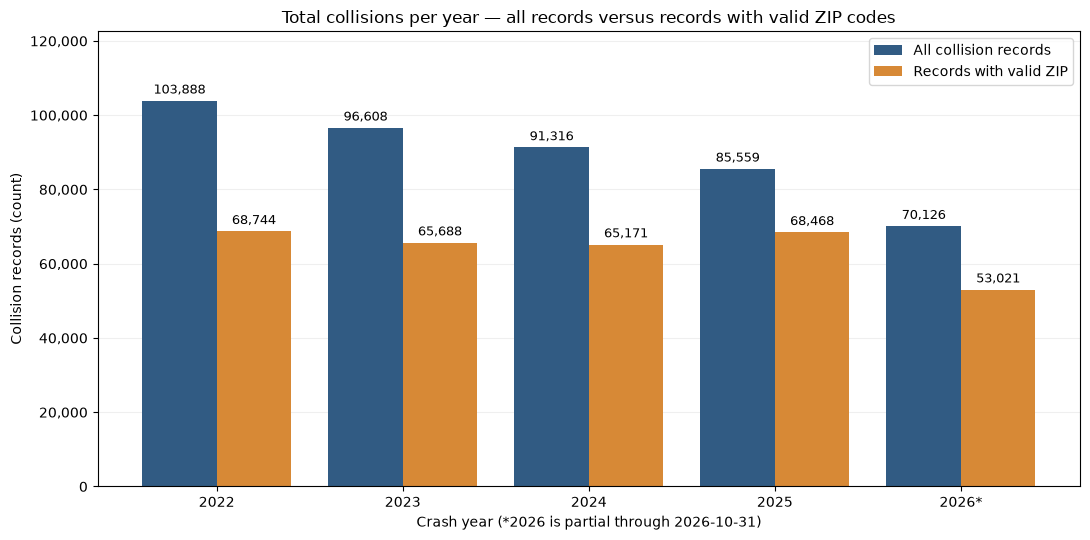

Plot source counts:


,year,input_records,valid_zip_records
0,2022,103888,68744
1,2023,96608,65688
2,2024,91316,65171
3,2025,85559,68468
4,2026,70126,53021


In [6]:
x = np.arange(len(year_coverage))
fig, ax = plt.subplots(figsize=(11, 5.5))
all_bars = ax.bar(x - 0.2, year_coverage['input_records'], width=0.4, label='All collision records', color='#315b83')
valid_bars = ax.bar(x + 0.2, year_coverage['valid_zip_records'], width=0.4, label='Records with valid ZIP', color='#d78936')
ax.bar_label(all_bars, labels=[f'{int(v):,}' for v in year_coverage['input_records']], padding=3, fontsize=9)
ax.bar_label(valid_bars, labels=[f'{int(v):,}' for v in year_coverage['valid_zip_records']], padding=3, fontsize=9)
labels = [f'{int(y)}*' if int(y) == latest_year else str(int(y)) for y in year_coverage['year']]
ax.set_xticks(x, labels)
ax.set_title('Total collisions per year — all records versus records with valid ZIP codes')
ax.set_xlabel(f'Crash year (*{latest_year} is partial through {latest_date.date()})')
ax.set_ylabel('Collision records (count)')
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.set_ylim(0, year_coverage['input_records'].max() * 1.18)
ax.legend(loc='upper right')
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()
print('Plot source counts:')
display(year_coverage[['year', 'input_records', 'valid_zip_records']])


## 7. Focused offline regression tests
Small synthetic fixtures are used **only for tests**, never mixed with the real input or output.
Tests cover explicit sums, ZIP exclusion, cross-year borough selection, case-insensitive factor
exclusions, both tie rules, input-order invariance, empty eligibility, int64 overflow protection,
rejected malformed source values, and real CSV writing/reloading/conflict behavior.
All temporary test files live in an ignored directory and are removed by `TemporaryDirectory`.


In [7]:
def read_aggregate(path):
    """Reload CSV identifiers/categories without treating legitimate text tokens as null."""
    types = {c: 'string' for c in ['zip_code', 'borough', 'top_contributing_factor', 'is_partial_year']}
    types.update({c: 'int64' for c in ['year'] + COUNT_COLUMNS})
    frame = pd.read_csv(path, dtype=types, keep_default_na=False, na_values=[''])
    require(frame.columns.tolist() == OUTPUT_COLUMNS, 'Export schema/order differs')
    frame['is_partial_year'] = parse_boolean_text(frame['is_partial_year'], 'is_partial_year')
    for column in ['year'] + COUNT_COLUMNS:
        require(pd.api.types.is_integer_dtype(frame[column]) and frame[column].notna().all(), f'Export {column} is not nonmissing integer')
        frame[column] = frame[column].astype('int64')
    return frame

def export_verified(frame, destination):
    """Verify a temporary CSV before promotion; preserve a different existing destination."""
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists():
        try:
            existing = read_aggregate(destination)
            pd.testing.assert_frame_equal(existing, frame, check_exact=True)
        except Exception as exc:
            raise FileExistsError(f'Preserving different/unreadable existing output: {destination}') from exc
        print('Identical existing output reused:', destination.name)
        return existing
    temporary = None
    try:
        with tempfile.NamedTemporaryFile(mode='w', encoding='utf-8', newline='', dir=destination.parent,
                                         prefix=f'.{destination.stem}_', suffix='.tmp', delete=False) as handle:
            temporary = Path(handle.name)
            frame.to_csv(handle, index=False)
        reloaded = read_aggregate(temporary)
        pd.testing.assert_frame_equal(reloaded, frame, check_exact=True)
        if destination.exists():
            raise FileExistsError(f'Destination appeared during export; preserving it: {destination}')
        temporary.replace(destination)
        temporary = None
        return reloaded
    finally:
        if temporary is not None:
            temporary.unlink(missing_ok=True)  # only this function's own temporary file

def make_test_source(specifications):
    """Construct clearly synthetic Stage 2 fixtures, independent of real records."""
    latest = max(s['year'] for s in specifications)
    rows = []
    for i, specification in enumerate(specifications):
        row = {c: pd.NA for c in EXPECTED_INPUT_COLUMNS}
        row.update({c: 0 for c in SOURCE_COUNTS})
        y = specification['year']
        row.update({'collision_id': f'synthetic-{i}', 'crash_date': pd.Timestamp(year=y, month=6, day=15),
                    'crash_time': '12:00', 'year': y, 'month': 6, 'hour': 12,
                    'latitude': np.nan, 'longitude': np.nan, 'is_partial_year': y == latest,
                    'zip_code': specification.get('zip_code'), 'borough': specification.get('borough'),
                    'contributing_factor_vehicle_1': specification.get('factor'),
                    'number_of_persons_injured': specification.get('injured', 0),
                    'number_of_motorist_injured': specification.get('injured', 0)})
        row['zip_missing'] = bool(pd.isna(row['zip_code']))
        row['extreme_injury'] = row['number_of_persons_injured'] >= 15
        rows.append(row)
    frame = pd.DataFrame(rows, columns=EXPECTED_INPUT_COLUMNS)
    for column in ['collision_id', 'zip_code', 'borough'] + FACTOR_COLUMNS + VEHICLE_COLUMNS:
        frame[column] = frame[column].astype('string')
    frame[SOURCE_COUNTS + ['year', 'month', 'hour']] = frame[SOURCE_COUNTS + ['year', 'month', 'hour']].astype('int64')
    frame[FLAGS] = frame[FLAGS].astype(bool)
    return frame

def expect_rejection(function, exception=ValueError):
    try:
        function()
    except exception:
        return
    raise AssertionError(f'Expected {exception.__name__} was not raised')

def run_focused_tests():
    passed = []
    fixture = make_test_source([
        {'zip_code': '10001', 'year': 2022, 'borough': 'Queens', 'factor': 'Zebra', 'injured': 1},
        {'zip_code': '10001', 'year': 2022, 'borough': 'Queens', 'factor': 'Alpha', 'injured': 20},
        {'zip_code': '10001', 'year': 2023, 'borough': 'Manhattan', 'factor': 'Following Too Closely', 'injured': 2},
        {'zip_code': '10002', 'year': 2023, 'borough': 'Bronx', 'factor': ' UnSpEcIfIeD '},
        {'zip_code': '10002', 'year': 2023, 'borough': 'Bronx', 'factor': 'does NOT apply'},
        {'zip_code': None, 'year': 2022, 'borough': None, 'factor': None, 'injured': 3},
    ])
    before = fixture.copy(deep=True)
    result = aggregate_zip_year(fixture)
    validate_aggregate(result, fixture)
    assert len(result) == 3 and result['collision_count'].sum() == 5
    assert result['persons_injured'].sum() == 23 and result['extreme_injury_count'].sum() == 1
    row = result.set_index(KEYS).loc[('10001', 2022)]
    assert row['collision_count'] == 2 and row['persons_injured'] == 21 and row['top_contributing_factor'] == 'Alpha'
    pd.testing.assert_frame_equal(before, fixture)
    passed.append('normal metrics, exact sums and source-frame preservation')
    years, totals = summarize_exclusions(fixture)
    assert years['excluded_missing_zip'].sum() == 1
    assert totals.set_index('metric').loc['persons_injured', 'excluded_missing_zip'] == 3
    assert len(result) == fixture.loc[fixture['zip_code'].notna(), KEYS].drop_duplicates().shape[0]
    passed.append('missing ZIP exclusion and casualty/key reconciliation')
    assert result.loc[result['zip_code'].eq('10001'), 'borough'].eq('Queens').all()
    modes, conflicts = borough_decisions(fixture.loc[fixture['zip_code'].notna()])
    assert modes['10001'] == 'Queens' and set(conflicts['records']) == {1, 2}
    assert deterministic_mode(pd.Series(['Queens', 'Bronx'], dtype='string')) == 'Bronx'
    passed.append('all-years ZIP borough mode, conflict counts and borough tie')
    assert pd.isna(result.set_index(KEYS).loc[('10002', 2023), 'top_contributing_factor'])
    assert informative_factors(pd.Series([None, '', '   ', 'Unspecified', ' DOES   NOT APPLY ', 'NA'], dtype='string')).isna().tolist() == [True, True, True, True, True, False]
    assert deterministic_mode(pd.Series(['zebra', 'Alpha'])) == 'Alpha'
    assert deterministic_mode(pd.Series(['alpha', 'Alpha'])) == 'Alpha'
    passed.append('factor exclusions, genuine missing mode and deterministic ties')
    for seed in [7, 19]:
        pd.testing.assert_frame_equal(result, aggregate_zip_year(fixture.sample(frac=1, random_state=seed)))
    passed.append('input-order invariance')
    all_missing = make_test_source([{'zip_code': None, 'year': 2023, 'borough': None, 'injured': 3}])
    empty = aggregate_zip_year(all_missing)
    assert empty.empty and empty.columns.tolist() == OUTPUT_COLUMNS
    validate_aggregate(empty, all_missing)
    unknown_borough = make_test_source([{'zip_code': '10001', 'year': 2023, 'borough': None, 'factor': 'NA'}])
    assert pd.isna(aggregate_zip_year(unknown_borough).iloc[0]['borough'])
    passed.append('all-missing ZIPs create no cells; unknown borough is not fabricated')
    malformed = []
    x = fixture.copy(); x.loc[0, 'zip_code'] = '10001.0'; malformed.append(x)
    x = fixture.copy(); x.loc[0, 'collision_id'] = pd.NA; malformed.append(x)
    x = fixture.copy(); x.loc[1, 'collision_id'] = x.loc[0, 'collision_id']; malformed.append(x)
    x = fixture.copy(); x.loc[0, 'crash_date'] = pd.NaT; malformed.append(x)
    x = fixture.copy(); x.loc[0, 'year'] = 2024; malformed.append(x)
    x = fixture.copy(); x.loc[0, 'number_of_persons_injured'] = -1; malformed.append(x)
    x = fixture.copy(); x['number_of_persons_injured'] = x['number_of_persons_injured'].astype(float); x.loc[0, 'number_of_persons_injured'] = 1.5; malformed.append(x)
    x = fixture.copy(); x['number_of_persons_injured'] = x['number_of_persons_injured'].astype(float); x.loc[0, 'number_of_persons_injured'] = np.nan; malformed.append(x)
    x = fixture.copy(); x.loc[0, 'zip_missing'] = True; malformed.append(x)
    x = fixture.copy(); x.loc[0, 'is_partial_year'] = True; malformed.append(x)
    x = fixture.copy(); x.loc[0, 'extreme_injury'] = True; malformed.append(x)
    malformed.append(fixture.drop(columns='year'))
    for x in malformed:
        expect_rejection(lambda x=x: aggregate_zip_year(x))
    expect_rejection(lambda: parse_boolean_text(pd.Series(['False', 'not-a-boolean'], dtype='string'), 'test'))
    passed.append('12 malformed source cases plus invalid Boolean text rejected')
    overflow = fixture.iloc[:2].copy()
    overflow['is_partial_year'] = True
    overflow['number_of_persons_injured'] = np.int64(INT64_MAX)
    overflow['number_of_motorist_injured'] = np.int64(INT64_MAX)
    overflow['extreme_injury'] = True
    expect_rejection(lambda: aggregate_zip_year(overflow))
    passed.append('aggregate int64 overflow rejected before summation')
    with tempfile.TemporaryDirectory(prefix='zip-year-tests-', dir=VALIDATION_DIR) as temporary:
        path = Path(temporary) / 'roundtrip.csv'
        back = export_verified(result, path)
        pd.testing.assert_frame_equal(back, result)
        pd.testing.assert_frame_equal(export_verified(empty, Path(temporary) / 'empty.csv'), empty)
        before_bytes = path.read_bytes()
        pd.testing.assert_frame_equal(export_verified(result, path), result)
        assert path.read_bytes() == before_bytes
        different = result.copy(); different.loc[0, 'collision_count'] += 1
        expect_rejection(lambda: export_verified(different, path), FileExistsError)
        assert path.read_bytes() == before_bytes
        label_case = result.copy(); label_case.loc[0, 'zip_code'] = '00123'; label_case.loc[0, 'top_contributing_factor'] = 'NA'
        label_path = Path(temporary) / 'literal_tokens.csv'
        label_back = export_verified(label_case, label_path)
        assert label_back.loc[0, 'zip_code'] == '00123' and label_back.loc[0, 'top_contributing_factor'] == 'NA'
        bad = Path(temporary) / 'bad.csv'; bad.write_text('unreadable schema\n1\n', encoding='utf-8')
        bad_bytes = bad.read_bytes()
        expect_rejection(lambda: export_verified(result, bad), FileExistsError)
        assert bad.read_bytes() == bad_bytes
    passed.append('real CSV round-trip, identical reuse, conflicts, leading zeros and literal NA preservation')
    boundary = make_test_source([
        {'zip_code': '10001', 'year': 2021, 'borough': 'Manhattan'},
        {'zip_code': '10001', 'year': 2022, 'borough': 'Manhattan'},
        {'zip_code': '10001', 'year': 2026, 'borough': 'Manhattan'},
        {'zip_code': '10001', 'year': 2026, 'borough': 'Manhattan'},
        {'zip_code': '10001', 'year': 2027, 'borough': 'Manhattan'},
    ])
    boundary['crash_date'] = pd.to_datetime(['2021-12-31', '2022-01-01', '2026-10-31', '2026-11-01', '2027-06-15'])
    boundary['month'] = boundary['crash_date'].dt.month.astype('int64')
    before_boundary = boundary.copy(deep=True)
    validate_source_frame(boundary)
    bounded, summary, partial = apply_common_scope(boundary)
    assert len(bounded) == 2 and summary['excluded_before_start'] == 1 and summary['excluded_on_or_after_end'] == 2
    assert bounded['crash_date'].tolist() == [pd.Timestamp('2022-01-01'), pd.Timestamp('2026-10-31')]
    assert partial == 2026 and bounded['is_partial_year'].tolist() == [False, True]
    pd.testing.assert_frame_equal(boundary, before_boundary)
    older = make_test_source([{'zip_code': '10001', 'year': 2023, 'borough': 'Manhattan'}])
    older['crash_date'] = pd.to_datetime(['2023-12-31']); older['month'] = 12; older['is_partial_year'] = False
    validate_source_frame(older)
    older_scoped, _, older_partial = apply_common_scope(older)
    assert older_partial is None and not older_scoped['is_partial_year'].any()
    passed.append('inclusive/exclusive scope boundaries, later-source partial flag and complete older-year portability')
    with tempfile.TemporaryDirectory(prefix='snapshot-portability-', dir=VALIDATION_DIR) as temporary:
        loaded_frames = []
        for timestamp in [0, 1]:
            path = Path(temporary) / f'snapshot_{timestamp}.csv.gz'
            with path.open('wb') as handle:
                with gzip.GzipFile(filename='', fileobj=handle, mode='wb', mtime=timestamp) as compressed:
                    compressed.write(fixture.to_csv(index=False).encode('utf-8'))
            loaded = read_stage2(path)
            validate_source_frame(loaded)
            loaded_frames.append(apply_common_scope(loaded)[0])
        assert file_sha256(Path(temporary) / 'snapshot_0.csv.gz') != file_sha256(Path(temporary) / 'snapshot_1.csv.gz')
        pd.testing.assert_frame_equal(aggregate_zip_year(loaded_frames[0]), aggregate_zip_year(loaded_frames[1]))
    passed.append('different gzip hashes and source counts accepted without snapshot-specific assertions')
    return passed

focused_test_results = run_focused_tests()
for i, result in enumerate(focused_test_results, 1):
    print(f'PASS {i}: {result}')
print('Focused regression groups passed:', len(focused_test_results))


Identical existing output reused: roundtrip.csv


PASS 1: normal metrics, exact sums and source-frame preservation
PASS 2: missing ZIP exclusion and casualty/key reconciliation
PASS 3: all-years ZIP borough mode, conflict counts and borough tie
PASS 4: factor exclusions, genuine missing mode and deterministic ties
PASS 5: input-order invariance
PASS 6: all-missing ZIPs create no cells; unknown borough is not fabricated
PASS 7: 12 malformed source cases plus invalid Boolean text rejected
PASS 8: aggregate int64 overflow rejected before summation
PASS 9: real CSV round-trip, identical reuse, conflicts, leading zeros and literal NA preservation
PASS 10: inclusive/exclusive scope boundaries, later-source partial flag and complete older-year portability
PASS 11: different gzip hashes and source counts accepted without snapshot-specific assertions
Focused regression groups passed: 11


## 8. Export and reload the integration handoff
Verify a temporary CSV before promoting it to `data/collisions_zip_year.csv`. An identical existing
export is reused; a different/unreadable output is preserved and reported as a conflict. Reload ZIPs
as strings and flags as explicit Boolean values. Re-run the full aggregate/source comparison after
export. The original gzip's hash must remain unchanged.


In [8]:
reloaded = export_verified(aggregate, OUTPUT_PATH)
validate_aggregate(reloaded, source)
assert reloaded['year'].between(SCOPE_START.year, SCOPE_END.year).all()
assert reloaded['is_partial_year'].eq(reloaded['year'].eq(partial_year)).all()
assert not reloaded.duplicated(KEYS).any()
assert source['crash_date'].ge(SCOPE_START).all() and source['crash_date'].lt(SCOPE_END).all()
print('Reloaded year range:', int(reloaded['year'].min()), 'to', int(reloaded['year'].max()), '| scope window ends before', SCOPE_END.date())
pd.testing.assert_frame_equal(aggregate, reloaded, check_exact=True)
assert file_sha256(INPUT_PATH) == input_hash_before, 'The Stage 2 source file changed'
ignore = subprocess.run(['git', 'check-ignore', '--quiet', str(OUTPUT_PATH)], capture_output=True, text=True)
assert ignore.returncode == 0, 'Generated CSV must be ignored by Git'
tracked_output = subprocess.run(['git', 'ls-files', '--', str(OUTPUT_PATH)], capture_output=True, text=True, check=True)
assert not tracked_output.stdout.strip(), 'Generated output must not be tracked'
print('PASS: full CSV round-trip, all aggregate checks, source hash unchanged, output ignored/untracked.')
print('Output:', OUTPUT_PATH, '| rows:', len(reloaded), '| columns:', len(reloaded.columns), '| bytes:', OUTPUT_PATH.stat().st_size)
print('Output SHA-256:', file_sha256(OUTPUT_PATH))
print('Execution completed using only the local handoff. See the handoff for the separately documented fresh-clone test.')


Reloaded year range: 2022 to 2026 | scope window ends before 2026-11-01
PASS: full CSV round-trip, all aggregate checks, source hash unchanged, output ignored/untracked.
Output: data\collisions_zip_year.csv | rows: 1040 | columns: 15 | bytes: 84684
Output SHA-256: d8d45f9a197c5dd8c0bfc09c6231681388c846ffe27b0be2f9418bb968c30b63
Execution completed using only the local handoff. See the handoff for the separately documented fresh-clone test.


## 9. Limitations and handoff to Issa
- **Selection bias:** all missing-ZIP exclusions and casualty losses are shown above after the common
  date filter. Missing ZIPs are never imputed, and these records stay in the source gzip.
- **Partial 2026:** January 1 through October 31, matching the housing analysis window. Actual source
  coverage is printed; an older handoff may end earlier. Do not compare partial-year totals with full
  years, annualize mechanically, or assume that a fixed date filter prevents historical revisions.
- **No exposure denominator:** counts are reported collisions/casualties, not exposure-adjusted rates.
- **Borough ambiguity:** the printed conflict table retains all observed labels and vote counts; the
  all-years modal label summarizes those observations without changing any source location.
- **Extreme events:** severe crashes stay in all casualty totals and are separately counted for later
  sensitivity analysis. `extreme_injury_count` counts crashes, not injured people.
- **Correlation only:** shared geography and year do not establish that construction causes collisions.
- **Integration:** both tables must use January 1, 2022 through October 31, 2026 and compatible actual
  coverage. This cutoff is applied to crash-level records before aggregation, not inferred afterward.

### Current executed handoff
The following executed Markdown output provides the actual row count, columns and reconciliation totals for the current input. These values are generated, not fixed assertions.

### Reproduce the CSV
1. Open the repository root in VS Code and select a `.venv` installed with
   `pip install -r requirements.txt`. Restart Kernel and Run All in this notebook.
2. The input is `data/collisions_step2.csv.gz`. If absent, either obtain a separately shared Stage 2
   handoff from Ahmed/Yassin or explicitly run `phase1_collisions_eda_cleaning_ahmed.ipynb` to retrieve
   and clean the live source. This notebook never downloads it. Record which method was actually used;
   a transferred verified dataset is **copied input**, not API regeneration. File hashes are provenance,
   never mandatory acceptance values. New snapshots can revise in-window records, so totals may differ.
3. The accepted output is **`data/collisions_zip_year.csv`**, with the exact columns listed above.
   ZIP codes must be read as strings. Use `pd.read_csv('data/collisions_zip_year.csv',
   dtype={'zip_code': 'string', 'borough': 'string', 'top_contributing_factor': 'string'},
   keep_default_na=False, na_values=[''])`; verify integer counts, Boolean flags and unique keys.
4. Before intentionally replacing a different old derived CSV, archive it under ignored `data/validation/`.
   The notebook reuses identical outputs and refuses to overwrite different ones. Never remove the input.
5. Issa joins the two aggregates with one-to-one ZIP/year key validation, documenting unmatched
   observations, borough differences and any zero-filling interpretation. No housing join is performed here.

### Fresh-clone verification method
A clean clone of the remote feature branch (whose source tree matches the recorded `origin/main` revision) receives only the two uncommitted candidate files
(this notebook and `AI_PROMPTS.txt`), since the changes are deliberately not committed or pushed yet.
Create a new `.venv` with Python 3.14.8, run `python -m pip install -r requirements.txt`, then
`python -m pip check`. Copy the verified Stage 2 gzip to the clone's relative `data/` path and record
its hash/provenance. Execute all notebook cells in a fresh project kernel from that clone's root.
This tests candidate reproducibility with a **copied** handoff; it does not test API regeneration.
The recorded execution method and actual results are reported below without claiming a VS Code UI run.
**Verification performed on 2026-11-09:** a clean remote feature-branch clone, new Python 3.14.8
`.venv`, unchanged `requirements.txt` installation and `pip check` passed. The uncommitted candidate
files were overlaid because no commit/push was authorized. All **9 code cells** ran in order with
counts **1–9**, zero errors, and **11 focused regression groups** passed. Execution used `nbclient`
with the clone's project kernel and root working directory; a VS Code UI button run is not claimed.
The Stage 2 input was **copied from the verified local export generated on 2026-11-07**, not
regenerated from the API. Independent checks and the resulting CSV matched the working run exactly.
This is evidence for that copied-input candidate test, not a promise of identical live-API totals.


In [9]:
from IPython.display import Markdown
metric_lines = '\n'.join(f'| `{column}` | {int(reloaded[column].sum()):,} |' for column in COUNT_COLUMNS)
column_list = ', '.join(f'`{column}`' for column in OUTPUT_COLUMNS)
handoff_results = f"""### Actual handoff results from this execution
- Agreed window: **2022-01-01 through 2026-10-31**, inclusive; 2026 is partial (January through October).
- Observed filtered dates: **{source_dates.min().date()} through {latest_date.date()}**.
- Input rows before / after the date filter: **{scope_summary['rows_before']:,} / {scope_summary['rows_after']:,}**; excluded by date: **{scope_summary['excluded_total']:,}**.
- Missing-ZIP exclusions after the date filter: **{len(excluded):,} ({100 * len(excluded) / len(source):.6f}%)**.
- Output: **{OUTPUT_PATH.as_posix()}**, **{len(reloaded):,} rows**, **{len(OUTPUT_COLUMNS)} columns**, **{reloaded['zip_code'].nunique()} ZIPs**.
- Exact columns, in order: {column_list}.
- Read ZIP codes as strings. Output keys are unique and every casualty sum reconciles to eligible filtered records.

| Metric | Reconciled output total |
|---|---:|
{metric_lines}
"""
display(Markdown(handoff_results))


### Actual handoff results from this execution
- Agreed window: **2022-01-01 through 2026-10-31**, inclusive; 2026 is partial (January through October).
- Observed filtered dates: **2022-01-01 through 2026-10-31**.
- Input rows before / after the date filter: **448,091 / 447,497**; excluded by date: **594**.
- Missing-ZIP exclusions after the date filter: **126,405 (28.247117%)**.
- Output: **data/collisions_zip_year.csv**, **1,040 rows**, **15 columns**, **228 ZIPs**.
- Exact columns, in order: `zip_code`, `year`, `borough`, `collision_count`, `persons_injured`, `persons_killed`, `pedestrians_injured`, `pedestrians_killed`, `cyclist_injured`, `cyclist_killed`, `motorist_injured`, `motorist_killed`, `extreme_injury_count`, `top_contributing_factor`, `is_partial_year`.
- Read ZIP codes as strings. Output keys are unique and every casualty sum reconciles to eligible filtered records.

| Metric | Reconciled output total |
|---|---:|
| `collision_count` | 321,092 |
| `persons_injured` | 169,577 |
| `persons_killed` | 720 |
| `pedestrians_injured` | 35,905 |
| `pedestrians_killed` | 372 |
| `cyclist_injured` | 19,336 |
| `cyclist_killed` | 61 |
| `motorist_injured` | 103,850 |
| `motorist_killed` | 205 |
| `extreme_injury_count` | 17 |


## Prompts used
The original implementation and this PR #10 fix request are recorded verbatim under Yassin in root-level `AI_PROMPTS.txt`. Yassin owns this collision aggregation; teammate source files are unchanged.
